<a href="https://colab.research.google.com/github/RAVINDUWEERASINGHE2002/ML_Practice2026/blob/main/kmeansclustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

%matplotlib inline

In [ ]:
from google.colab import files


uploaded = files.upload()

Saving income.csv to income.csv


In [ ]:
df = pd.read_csv('income.csv')
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


In [ ]:
print("Shape of the dataset:", df.shape)
# Expected: (22, 3)

Shape of the dataset: (22, 3)


In [ ]:
print(df.isnull().sum())

Name         0
Age          0
Income($)    0
dtype: int64


In [ ]:
X = df[['Age','Income($)']]

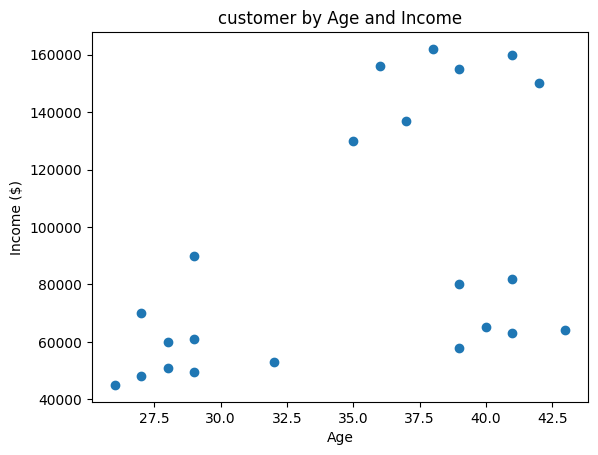

In [ ]:
plt.scatter(X['Age'], X['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.title('customer by Age and Income')
plt.show()

In [ ]:
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)

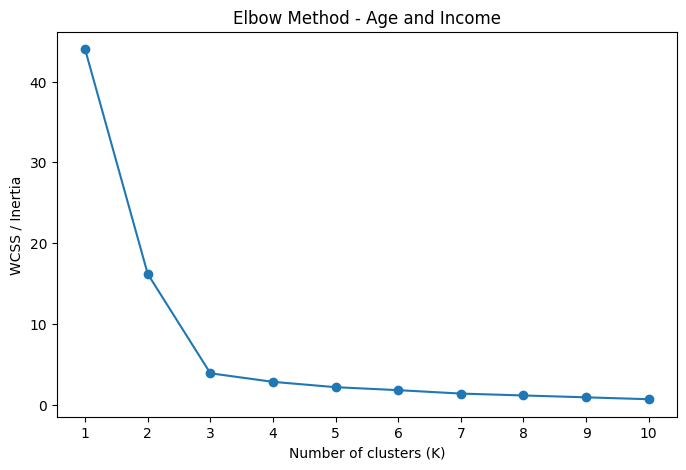

In [ ]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.title('Elbow Method - Age and Income')
plt.xticks(range(1, 11))
plt.show()

In [ ]:
chosen_k = 3

model = KMeans(
    n_clusters=chosen_k,
    init='k-means++',
    n_init=10,
    random_state=42
)

labels = model.fit_predict(X_scaled)

In [ ]:
df['Cluster'] = labels

In [ ]:
display(df.head())

,Name,Age,Income($),Cluster
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,0


In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,7
1,9
2,6


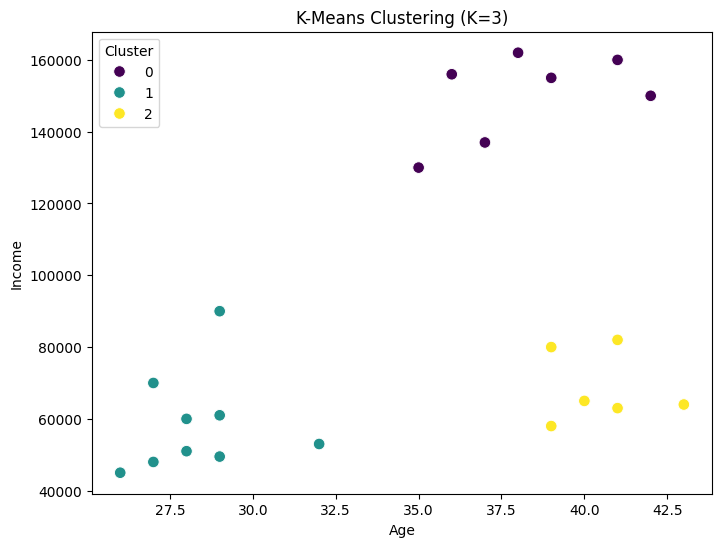

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='Age',
    y='Income($)',
    hue='Cluster',
    data=df,
    palette='viridis',
    s=70
)
plt.title(f'K-Means Clustering (K={chosen_k})')
plt.xlabel('Age')
plt.ylabel('Income')
plt.legend(title='Cluster')
plt.show()

# **Task 02**

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Mall_Customers (1).csv to Mall_Customers (1) (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler   # Note: MinMaxScaler this time

%matplotlib inline

In [ ]:
df = pd.read_csv('Mall_Customers (1).csv')


In [ ]:
df.shape

(200, 5)

In [ ]:
print(df.isnull().sum())

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


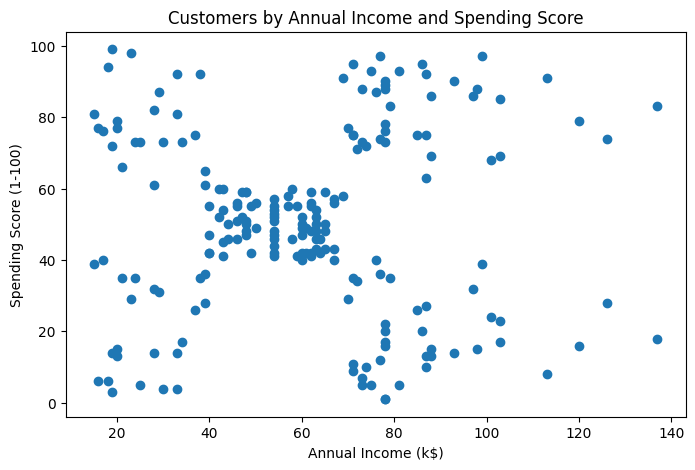

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customers by Annual Income and Spending Score')
plt.show()

In [ ]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

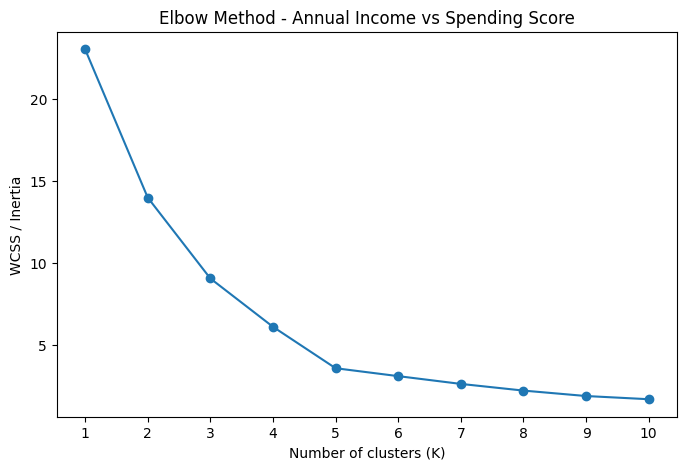

In [ ]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.title('Elbow Method - Annual Income vs Spending Score')
plt.xticks(range(1, 11))
plt.show()

In [ ]:
chosen_k = 5   # based on the elbow

model = KMeans(
    n_clusters=chosen_k,
    init='k-means++',
    n_init=10,
    random_state=42
)

labels = model.fit_predict(X_scaled)

In [ ]:
df['Cluster'] = labels
display(df.head())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,0
2,3,Female,20,16,6,4
3,4,Female,23,16,77,0
4,5,Female,31,17,40,4


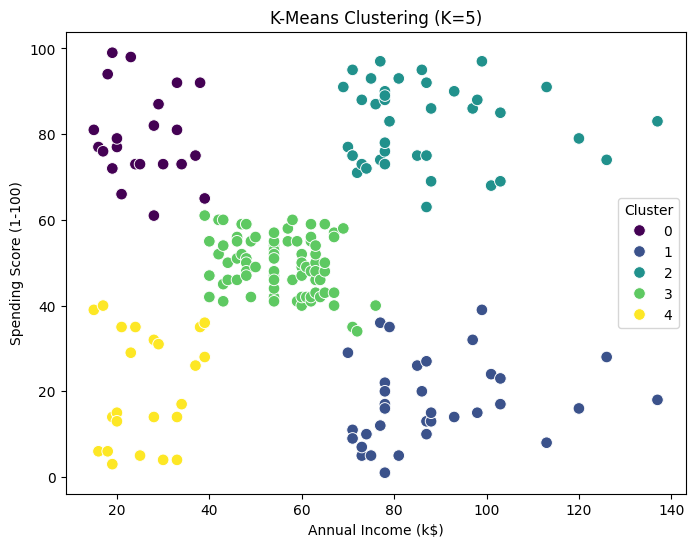

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    data=df,
    palette='viridis',
    s=70
)
plt.title(f'K-Means Clustering (K={chosen_k})')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.show()